# Лабораторная работа 2. Классификация. Нейронные сети

## 1. Введение

Цель работы – изучить классификацию в Scikit-Learn, построить нейросеть TensorFlow/Keras и наблюдать обучение в TensorBoard. На данных Rice (Cammeo and Osmancik) исследуются четыре варианта наивного Байеса, дерево решений, LDA, SVM и kNN, а также полносвязная нейросеть.

Для всех методов рассчитываются Accuracy, Precision, Recall, F1 и ROC-AUC. Положительный класс – **Cammeo (1)**, отрицательный – **Osmancik (0)**. Критерий настройки и выбора – ROC-AUC. Выделены три непересекающихся набора: train 60%, validation 20%, test 20%. Все модели обучаются на train; validation используется для выбора параметров нейросети и сравнения подходов, а test – только для итоговой оценки.

Код представлен последовательно: данные → разбиение → модели → подбор → нейросеть → сравнение. Общими функциями вынесены только расчёт метрик и создание нейросети.

In [34]:
import os
from pathlib import Path
from datetime import datetime
import json

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, Binarizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

SEED = 42
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
if not (BASE / 'data/rice.csv').exists():
    BASE = BASE / 'lab2'
RESULTS = BASE / 'results'
PLOTS = RESULTS / 'plots'
MODELS = RESULTS / 'models'
for folder in [RESULTS, PLOTS, MODELS, RESULTS / 'classical_cv', RESULTS / 'neural_histories']:
    folder.mkdir(parents=True, exist_ok=True)
LOGS = BASE / 'logs/tensorboard' / datetime.now().strftime('%Y%m%d-%H%M%S')

Подключены библиотеки для таблиц, графиков и обучения. `SEED=42` фиксирует случайность Python, NumPy и TensorFlow через `set_random_seed`; для разбиения и методов Scikit-Learn seed указывается отдельно. Детерминированный режим и два вычислительных потока позволяют повторить расчёты на CPU в том же окружении. Каталоги создаются один раз: результаты – в `results`, события TensorBoard – в отдельном каталоге текущего запуска.

## 2. Выбор и подготовка датасета

Использован [Rice (Cammeo and Osmancik), UCI](https://archive.ics.uci.edu/dataset/545/rice%2Bcammeo%2Band%2Bosmancik), DOI [10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z). Локальная CSV-копия получена из исходного ARFF, сохранённого рядом в `data`.

| Признак | Смысл |
| :--- | :--- |
| Area | Площадь зерна в пикселях |
| Perimeter | Периметр зерна |
| Major_Axis_Length | Длина большой оси |
| Minor_Axis_Length | Длина малой оси |
| Eccentricity | Эксцентриситет |
| Convex_Area | Площадь выпуклой оболочки |
| Extent | Отношение площади зерна к ограничивающему прямоугольнику |
| Class | Сорт риса, целевая переменная |

In [35]:
df = pd.read_csv(BASE / 'data/rice.csv')
df.info()
print('Пропуски:', df.isna().sum().sum())
print('Дубликаты:', df.duplicated().sum())
df = df.dropna()
X = df.drop(columns='Class')
y = df['Class'].map({'Osmancik': 0, 'Cammeo': 1})
print(df['Class'].value_counts())
print(X.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   str    
dtypes: float64(7), str(1)
memory usage: 238.3 KB
Пропуски: 0
Дубликаты: 0
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64
           Area  Perimeter  Major_Axis_Length  Minor_Axis_Length  \
count   3810.00    3810.00            3810.00            3810.00   
mean   12667.73     454.24             188.78              86.31   
std     1732.37      35.60              17.45               5.73   
min     7551

Загружено **3810 объектов**, семь числовых признаков и цель. Классы: **1630 Cammeo** и **2180 Osmancik**. Пропусков и полных дубликатов нет, поэтому `dropna()` не удалил строки. Цель явно закодирована: Cammeo=1, Osmancik=0. Категориальных входных признаков нет. Признаки имеют разные масштабы: площади измеряются тысячами пикселей, а Eccentricity и Extent лежат в пределах единицы. Поэтому далее используется стандартизация.

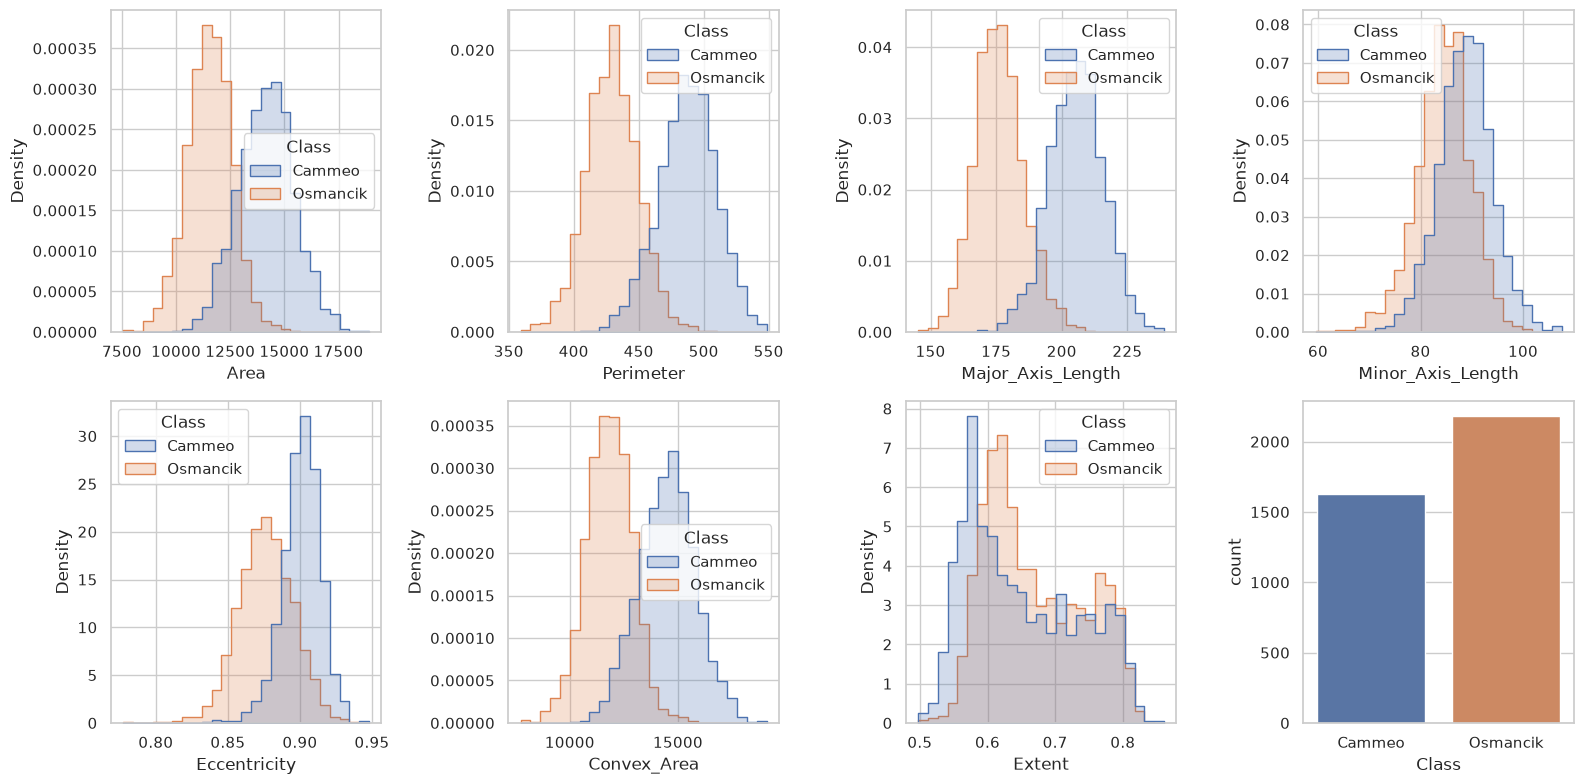

In [36]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, X.columns):
    sns.histplot(data=df, x=column, hue='Class', bins=25, element='step',
                 stat='density', common_norm=False, ax=ax)
sns.countplot(data=df, x='Class', hue='Class', legend=False, ax=axes.flat[-1])
plt.tight_layout()
plt.savefig(PLOTS / '01_distributions.png')
plt.show()

Для семи признаков показаны распределения по сортам, последняя панель содержит количества классов. Плотности нормированы отдельно внутри каждого сорта, поэтому большее число Osmancik не увеличивает искусственно высоту его распределения. У Cammeo заметно выше типичные площадь, периметр и длина большой оси, но распределения перекрываются. Один признак не обеспечивает безошибочного разделения, поэтому сравниваются многомерные классификаторы.

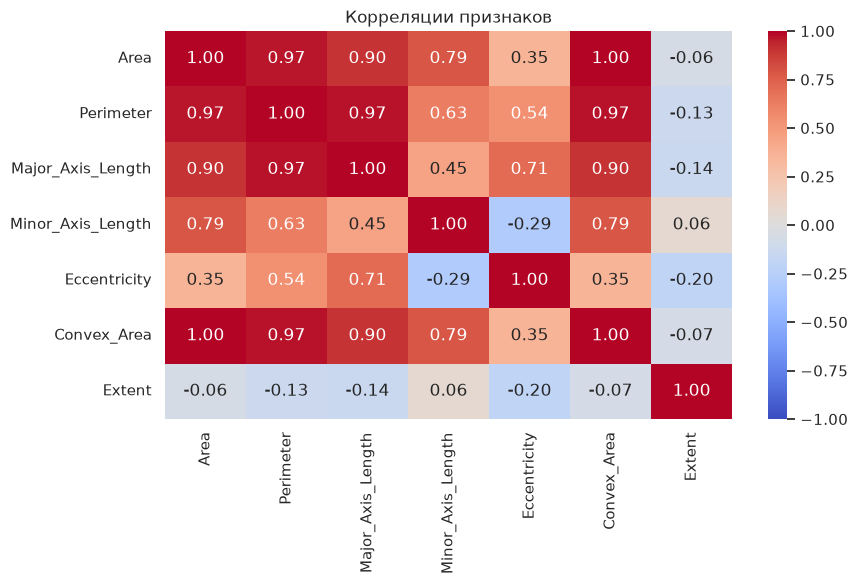

In [37]:
plt.figure(figsize=(9, 6))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляции признаков')
plt.tight_layout()
plt.savefig(PLOTS / '02_correlations.png')
plt.show()

Area и Convex_Area сильно связаны: **r≈0,99894**. Геометрические признаки частично дублируют информацию. Это может ограничивать наивный Байес, предполагающий условную независимость признаков внутри класса, и влияет на оценку ковариации в LDA. Признаки автоматически не удаляются: сравнивается качество методов на одном исходном наборе. Матрица используется для описания данных; параметры обучаемых преобразований по ней не настраиваются.

## 3. Разбиение выборки

Сначала выделяется 20% в test, затем четверть оставшихся данных – в validation. Итоговые доли: 60/20/20. Разбиения стратифицированы: доли сортов сохраняются. Пять фолдов `StratifiedKFold` применяются только внутри train.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=SEED, stratify=y_train
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
splits = pd.Series(index=X.index, dtype='str', name='split')
for name, part in [('train', X_train), ('validation', X_val), ('test', X_test)]:
    splits.loc[part.index] = name
splits.to_csv(RESULTS / 'split_assignment.csv', index_label='row_id')

Train: (2286, 7) Validation: (762, 7) Test: (762, 7)


Получено **2286 обучающих объектов**, **762 validation** и **762 test**, в каждой матрице семь признаков. В первой строке разбиения `X_train` временно содержит 80% данных; второй вызов выделяет из него validation и оставляет окончательный train из 60%. Дальше обучающие объекты не объединяются с validation, дополнительного переобучения нет. Поэтому все девять итоговых методов оцениваются после обучения на одних и тех же 2286 объектах. Индексы разбиения сохранены в `split_assignment.csv`.

## 4. Методы классификации и метрики

In [39]:
def calculate_metrics(y_true, y_pred, scores):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, scores),
    }

Одна функция рассчитывает одинаковые пять показателей для всех моделей. Accuracy – доля верных меток. Precision=TP/(TP+FP), Recall=TP/(TP+FN), F1 – их гармоническое среднее; эти три показателя относятся к Cammeo (1). ROC-AUC оценивает ранжирование по непрерывным оценкам: вероятностям или `decision_function` SVM. В ROC-AUC передаются именно `scores`, а не готовые метки `y_pred`. Нейросеть использует фиксированный порог 0,5; он не подбирается по test.

In [40]:
models = {
    'GaussianNB': Pipeline([('scale', StandardScaler()), ('model', GaussianNB())]),
    'MultinomialNB': Pipeline([
        ('bins', KBinsDiscretizer(n_bins=5, encode='onehot-dense', strategy='quantile', subsample=None)),
        ('model', MultinomialNB()),
    ]),
    'ComplementNB': Pipeline([
        ('bins', KBinsDiscretizer(n_bins=5, encode='onehot-dense', strategy='quantile', subsample=None)),
        ('model', ComplementNB()),
    ]),
    'BernoulliNB': Pipeline([
        ('scale', StandardScaler()), ('binary', Binarizer()),
        ('model', BernoulliNB(binarize=None)),
    ]),
    'Decision Tree': Pipeline([('model', DecisionTreeClassifier(random_state=SEED))]),
    'LDA': Pipeline([('scale', StandardScaler()), ('model', LinearDiscriminantAnalysis())]),
    'SVM': Pipeline([('scale', StandardScaler()), ('model', SVC(random_state=SEED))]),
    'kNN': Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier())]),
}
param_grids = {
    'GaussianNB': {'model__var_smoothing': [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4, 1e-2]},
    'MultinomialNB': {'bins__n_bins': [3, 5, 8], 'model__alpha': [0.01, 0.1, 1, 10]},
    'ComplementNB': {'bins__n_bins': [3, 5, 8], 'model__alpha': [0.01, 0.1, 1, 10]},
    'BernoulliNB': {'binary__threshold': [-0.5, 0, 0.5], 'model__alpha': [0.01, 0.1, 1, 10]},
    'Decision Tree': {'model__max_depth': [2, 3, 5, 8, None],
                      'model__min_samples_leaf': [1, 5, 15], 'model__criterion': ['gini', 'entropy']},
    'LDA': [{'model__solver': ['svd'], 'model__tol': [1e-4, 1e-2]},
            {'model__solver': ['lsqr'], 'model__shrinkage': [None, 'auto', 0.1, 0.5, 0.9]}],
    'SVM': [{'model__kernel': ['rbf'], 'model__C': [0.1, 1, 10, 100],
             'model__gamma': ['scale', 0.01, 0.1, 1]},
            {'model__kernel': ['linear'], 'model__C': [0.1, 1, 10, 100]}],
    'kNN': {'model__n_neighbors': [3, 5, 11, 21, 41],
            'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]},
}

Заданы восемь классических вариантов:

- **GaussianNB** – нормальные условные распределения числовых признаков.
- **MultinomialNB и ComplementNB** – квантильная дискретизация превращает измерения в индикаторы интервалов, пригодные как неотрицательное счётное представление. Исходные площади и длины не трактуются как частоты событий.
- **BernoulliNB** – стандартизация и бинаризация по порогу; это отдельный вариант с потерей части исходной информации.
- **Decision Tree** – пороговые правила, масштабирование не требуется.
- **LDA** – линейная граница при общей ковариации классов.
- **SVM** – разделяющий зазор, линейное или RBF-ядро.
- **kNN** – голосование ближайших соседей.

В `models` отдельно видны шаги предобработки, в `param_grids` – проверяемые настройки. `model__C`, например, означает параметр `C` шага `model` внутри Pipeline. При CV все обучаемые шаги заново настраиваются на обучающей части фолда.

## 5. Настройка гиперпараметров

In [41]:
best_models, searches = {}, {}
tuning_rows, validation_rows = [], []
for name, model in models.items():
    baseline_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    search = GridSearchCV(model, param_grids[name], cv=cv, scoring='roc_auc', error_score='raise')
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    searches[name] = search
    table = pd.DataFrame(search.cv_results_)
    table.to_csv(RESULTS / 'classical_cv' / f'{name}.csv', index=False)
    tuning_rows.append({'Модель': name, 'CV до': baseline_auc, 'CV после': search.best_score_,
                        'CV std': table.loc[search.best_index_, 'std_test_score'],
                        'Параметры': str(search.best_params_)})
    prediction = search.predict(X_val)
    if name == 'SVM':
        scores = search.decision_function(X_val)
    else:
        scores = search.predict_proba(X_val)[:, 1]
    validation_rows.append({'Модель': name, **calculate_metrics(y_val, prediction, scores)})
    joblib.dump(search.best_estimator_, MODELS / f'{name}.joblib')
    print(name, search.best_params_, 'CV AUC:', round(search.best_score_, 5), flush=True)

tuning_table = pd.DataFrame(tuning_rows)
tuning_table.to_csv(RESULTS / 'classical_tuning.csv', index=False)
print(tuning_table.to_string(index=False))

GaussianNB {'model__var_smoothing': 0.0001} CV AUC: 0.97475
MultinomialNB {'bins__n_bins': 8, 'model__alpha': 1} CV AUC: 0.97384
ComplementNB {'bins__n_bins': 8, 'model__alpha': 1} CV AUC: 0.97384
BernoulliNB {'binary__threshold': 0, 'model__alpha': 0.01} CV AUC: 0.95799
Decision Tree {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 15} CV AUC: 0.97498
LDA {'model__solver': 'svd', 'model__tol': 0.0001} CV AUC: 0.97965
SVM {'model__C': 100, 'model__kernel': 'linear'} CV AUC: 0.97952
kNN {'model__n_neighbors': 41, 'model__p': 2, 'model__weights': 'uniform'} CV AUC: 0.97683
       Модель    CV до  CV после   CV std                                                                             Параметры
   GaussianNB 0.974742  0.974746 0.007671                                                      {'model__var_smoothing': 0.0001}
MultinomialNB 0.972277  0.973840 0.008213                                                {'bins__n_bins': 8, 'model__alpha': 1}
 Comp

Для каждого метода сначала рассчитан базовый CV ROC-AUC, затем `GridSearchCV` выбрал параметры по той же метрике и пяти тем же фолдам. `best_estimator_` автоматически обучен на всём train; дополнительные обёртки и повторный `fit` не нужны. Валидационные данные используются только в `predict`, а test в этом блоке вообще не используется. Лучшие параметры означают лучший результат среди проверенных вариантов, а не глобальный оптимум.

Проверены **120 конфигураций**. Наибольший прирост CV AUC у **Decision Tree**: 0,88651 → 0,97498. У некоторых методов изменение настроек почти не меняет AUC. На границе сетки не следует считать найденное значение доказанным глобальным оптимумом. Например, 41 сосед и C=100 – максимальные проверенные значения, а не пределы метода.

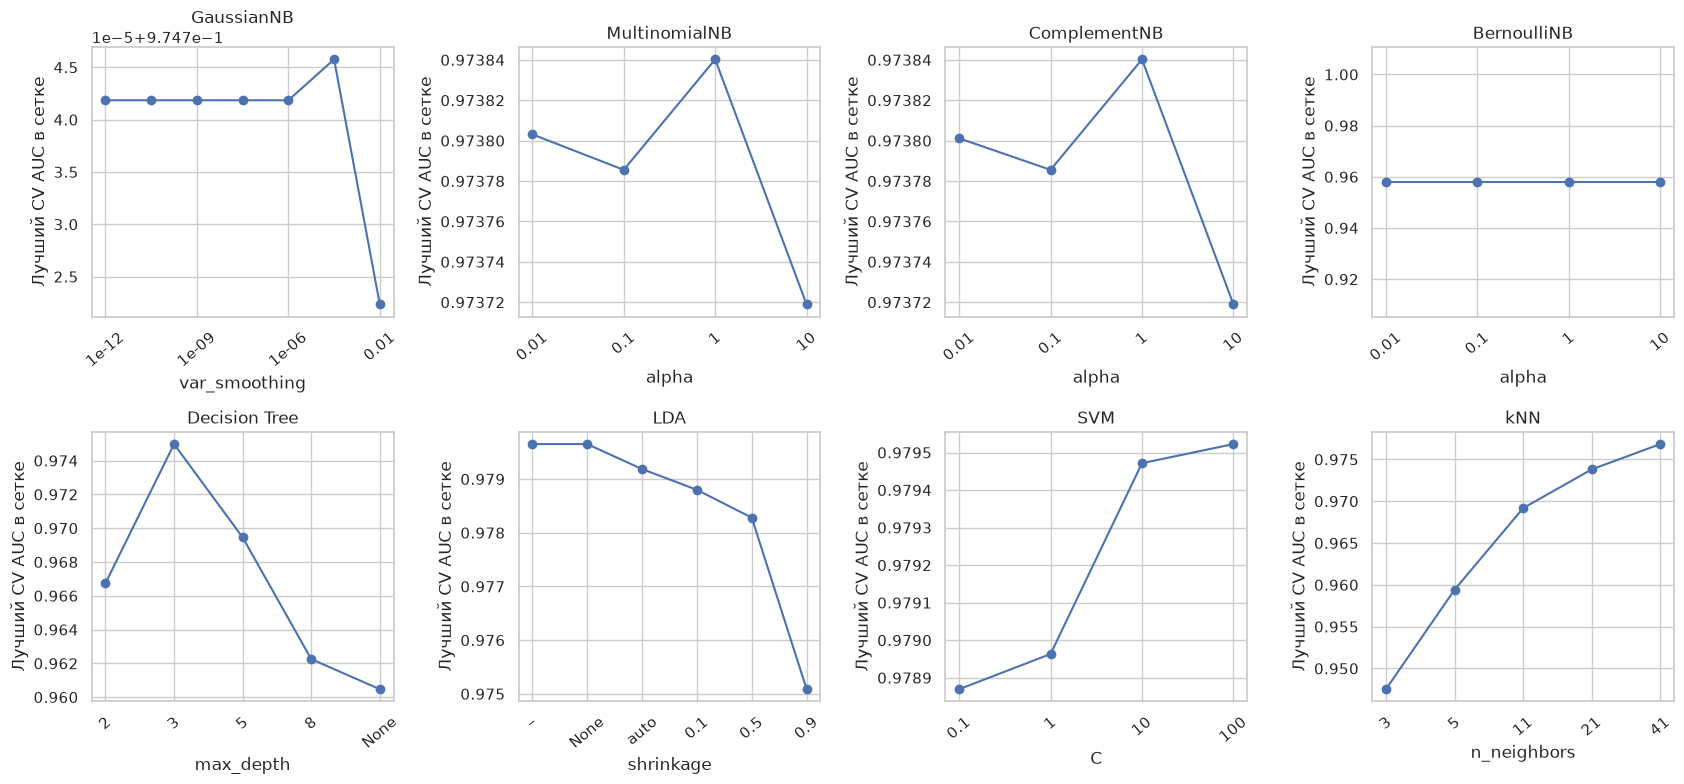

In [42]:
parameters = ['model__var_smoothing', 'model__alpha', 'model__alpha', 'model__alpha',
              'model__max_depth', 'model__shrinkage', 'model__C', 'model__n_neighbors']
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (name, search), parameter in zip(axes.flat, searches.items(), parameters):
    values = [str(params.get(parameter, '–')) for params in search.cv_results_['params']]
    table = pd.DataFrame({'Значение': values, 'AUC': search.cv_results_['mean_test_score']})
    curve = table.groupby('Значение', sort=False)['AUC'].max()
    curve.plot(marker='o', ax=ax)
    ax.set_title(name)
    ax.set_xlabel(parameter.replace('model__', ''))
    ax.set_ylabel('Лучший CV AUC в сетке')
    ax.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.savefig(PLOTS / '03_parameter_effects.png')
plt.show()

Для каждого значения показанного параметра взят **лучший CV AUC среди остальных настроек в сетке**. Это помогает увидеть, какие значения позволили получить более высокое качество. Остальные параметры могут различаться, поэтому графики нельзя интерпретировать как изолированное влияние одного фактора. У LDA символ «–» соответствует варианту `svd`, в котором shrinkage не используется. Полные сочетания и результаты каждого фолда сохранены в `results/classical_cv`.

## 6. Нейронная сеть на TensorFlow

In [43]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype('float32')
X_val_scaled = scaler.transform(X_val).astype('float32')
X_test_scaled = scaler.transform(X_test).astype('float32')

def create_network(layers, activation):
    network = tf.keras.Sequential([tf.keras.Input(shape=(7,))])
    for neurons in layers:
        network.add(tf.keras.layers.Dense(neurons, activation=activation))
    network.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    network.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return network

# Название, нейроны в скрытых слоях, активация, эпохи, размер батча.
experiments = [
    ('base', (16,), 'relu', 40, 32),
    ('epochs10', (16,), 'relu', 10, 32),
    ('epochs80', (16,), 'relu', 80, 32),
    ('batch16', (16,), 'relu', 40, 16),
    ('batch64', (16,), 'relu', 40, 64),
    ('width8', (8,), 'relu', 40, 32),
    ('width32', (32,), 'relu', 40, 32),
    ('depth2', (16, 16), 'relu', 40, 32),
    ('depth3', (16, 16, 16), 'relu', 40, 32),
    ('tanh', (16,), 'tanh', 40, 32),
    ('sigmoid', (16,), 'sigmoid', 40, 32),
]
create_network((16,), 'relu').summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

StandardScaler обучен только на train. К validation и test применён исключительно `transform`, так что их средние и масштабы не участвуют в настройке. Нейросеть получает семь входов; базовая архитектура 7→16→1 содержит **145 параметров**. Скрытая ReLU задаёт нелинейность, выходная sigmoid даёт оценку вероятности Cammeo. Используются Adam с шагом по умолчанию 0,001 и binary cross-entropy.

В каждом кортеже эксперимента последовательно указаны название, скрытые слои, активация, эпохи и батч. Проверяются 11 вариантов. Относительно `base` меняется один фактор: 10/80 эпох вместо 40, батч 16/64 вместо 32, 8/32 нейрона вместо 16, два/три слоя вместо одного или tanh/sigmoid вместо ReLU.

In [44]:
nn_rows, histories = [], {}
best_auc = -1
for name, layers, activation, epochs, batch in experiments:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    network = create_network(layers, activation)
    tensorboard = tf.keras.callbacks.TensorBoard(log_dir=str(LOGS / name), profile_batch=0)
    history = network.fit(
        X_train_scaled, y_train.to_numpy(), validation_data=(X_val_scaled, y_val.to_numpy()),
        epochs=epochs, batch_size=batch, callbacks=[tensorboard], verbose=0,
    )
    scores = network.predict(X_val_scaled, verbose=0).ravel()
    metrics = calculate_metrics(y_val, (scores >= 0.5).astype(int), scores)
    nn_rows.append({'Run': name, 'Слои': str(layers), 'Активация': activation,
                    'Эпохи': epochs, 'Батч': batch, **metrics})
    histories[name] = history.history
    pd.DataFrame(history.history).to_csv(RESULTS / 'neural_histories' / f'{name}.csv', index=False)
    if metrics['ROC-AUC'] > best_auc:
        best_auc = metrics['ROC-AUC']
        best_network, best_run = network, name
        best_nn_metrics = metrics
    print(name, 'Validation AUC:', round(metrics['ROC-AUC'], 5), flush=True)

nn_table = pd.DataFrame(nn_rows)
nn_table.to_csv(RESULTS / 'neural_experiments.csv', index=False)
best_network.save(MODELS / 'tensorflow_mlp.keras')
joblib.dump(scaler, MODELS / 'tensorflow_scaler.joblib')
print(nn_table.round(5).to_string(index=False))
print('Лучшая конфигурация:', best_run)

base Validation AUC: 0.9794
epochs10 Validation AUC: 0.98012
epochs80 Validation AUC: 0.97934
batch16 Validation AUC: 0.9792
batch64 Validation AUC: 0.97945
width8 Validation AUC: 0.97955
width32 Validation AUC: 0.97963
depth2 Validation AUC: 0.97936
depth3 Validation AUC: 0.97861
tanh Validation AUC: 0.97953
sigmoid Validation AUC: 0.98
     Run         Слои Активация  Эпохи  Батч  Accuracy  Precision  Recall      F1  ROC-AUC
    base        (16,)      relu     40    32   0.93701    0.92121 0.93252 0.92683  0.97940
epochs10        (16,)      relu     10    32   0.93438    0.91566 0.93252 0.92401  0.98012
epochs80        (16,)      relu     80    32   0.93701    0.92378 0.92945 0.92661  0.97934
 batch16        (16,)      relu     40    16   0.93701    0.92121 0.93252 0.92683  0.97920
 batch64        (16,)      relu     40    64   0.93832    0.91892 0.93865 0.92868  0.97945
  width8         (8,)      relu     40    32   0.93832    0.92145 0.93558 0.92846  0.97955
 width32        (32,)  

Нейросеть обучается обычным вызовом `fit` с NumPy-массивами и явно переданной validation. Перед каждым запуском сбрасывается seed. Каждая конфигурация проходит заданное число эпох полностью; EarlyStopping и восстановление весов к ранней эпохе не используются. Для сравнения берутся веса последней эпохи. Лучший экземпляр сети сохраняется в `best_network` по точному ROC-AUC Scikit-Learn на validation; test на выбор не влияет. TensorBoard подключён одной стандартной callback.

Выбран **epochs10**: скрытые слои (16,), активация relu, 10 эпох, батч 32. Validation ROC-AUC = **0,98012**, Accuracy = **0,93438**, F1 = **0,92401**.

- **Эпохи** – validation ROC-AUC: `epochs10`: 0,98012, `base`: 0,97940, `epochs80`: 0,97934.
- **Размер батча** – validation ROC-AUC: `batch16`: 0,97920, `base`: 0,97940, `batch64`: 0,97945.
- **Число нейронов** – validation ROC-AUC: `width8`: 0,97955, `base`: 0,97940, `width32`: 0,97963.
- **Число слоёв** – validation ROC-AUC: `base`: 0,97940, `depth2`: 0,97936, `depth3`: 0,97861.
- **Активация** – validation ROC-AUC: `base`: 0,97940, `tanh`: 0,97953, `sigmoid`: 0,98000.

Сравнения относятся к одному seed и одному разбиению. Небольшое преимущество не устанавливает универсально лучшую архитектуру. Все факторы менялись по одному относительно baseline, поэтому различия в таблице удобно связывать с конкретной настройкой.

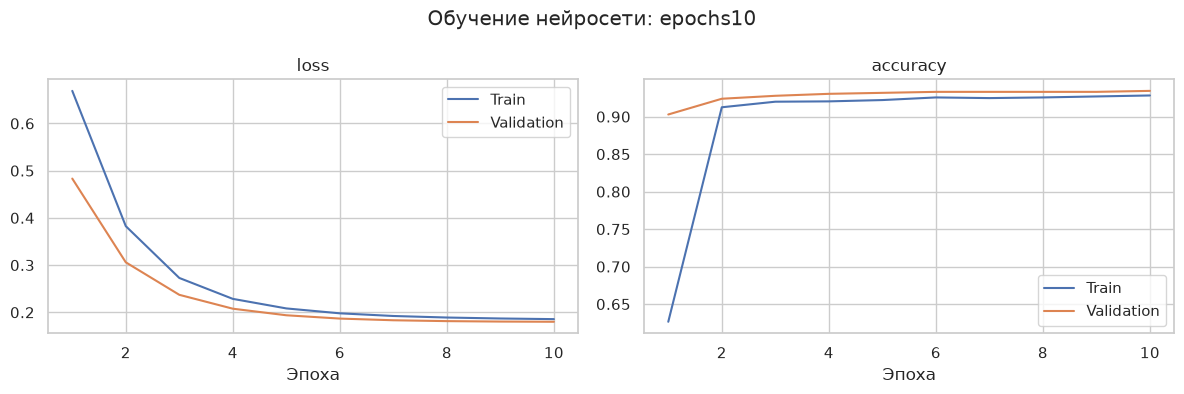

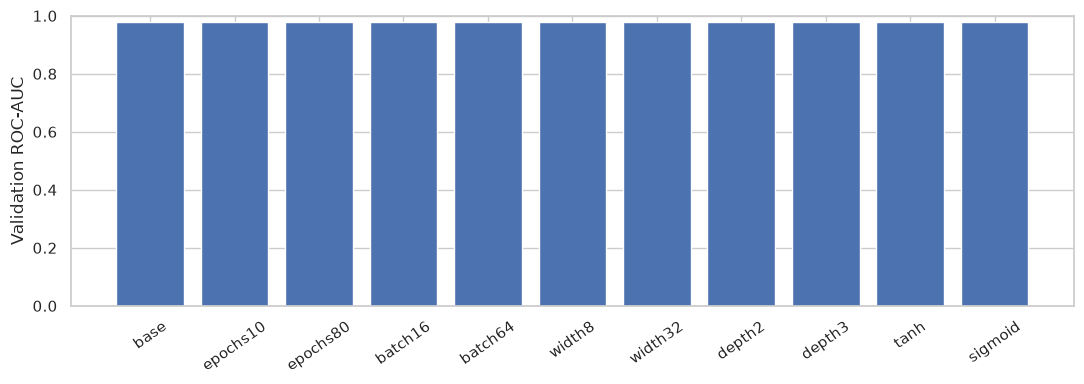

In [45]:
history = histories[best_run]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(range(1, len(history[metric]) + 1), history[metric], label='Train')
    ax.plot(range(1, len(history[metric]) + 1), history['val_' + metric], label='Validation')
    ax.set(title=metric, xlabel='Эпоха')
    ax.legend()
plt.suptitle(f'Обучение нейросети: {best_run}')
plt.tight_layout()
plt.savefig(PLOTS / '04_learning_curves.png')
plt.show()

plt.figure(figsize=(11, 4))
plt.bar(nn_table['Run'], nn_table['ROC-AUC'])
plt.ylabel('Validation ROC-AUC')
plt.ylim(0, 1)
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(PLOTS / '05_neural_experiments.png')
plt.show()

У выбранной сети **epochs10** loss на train изменился с 0,66899 до 0,18557, на validation – с 0,48323 до 0,17998. Accuracy последней эпохи: train=0,92826, validation=0,93438. Минимальный validation loss наблюдался на эпохе 10; к этой эпохе веса не восстанавливались. Разрыв кривых помогает обсуждать возможное переобучение, но не доказывает его причину.

На первом рисунке показаны train и validation loss/accuracy выбранной сети. Так можно проследить сходимость и заметить расхождение поведения на знакомых и новых объектах. На втором рисунке сравнивается validation ROC-AUC всех 11 конфигураций; шкала начинается с нуля. Числа в таблице лучше показывают небольшие различия, чем высота близких столбцов.

Логи каждого запуска записаны в TensorBoard. Из корня проекта с активированным окружением выполните:

```bash
tensorboard --logdir lab2/logs/tensorboard --port 6006
```

Откройте `http://localhost:6006` и выберите текущую группу запусков. В Time Series / Scalars теги `epoch_loss` и `epoch_accuracy` показываются отдельно у `train` и `validation`: это четыре обязательных ряда. Для каждой конфигурации создан свой подкаталог.

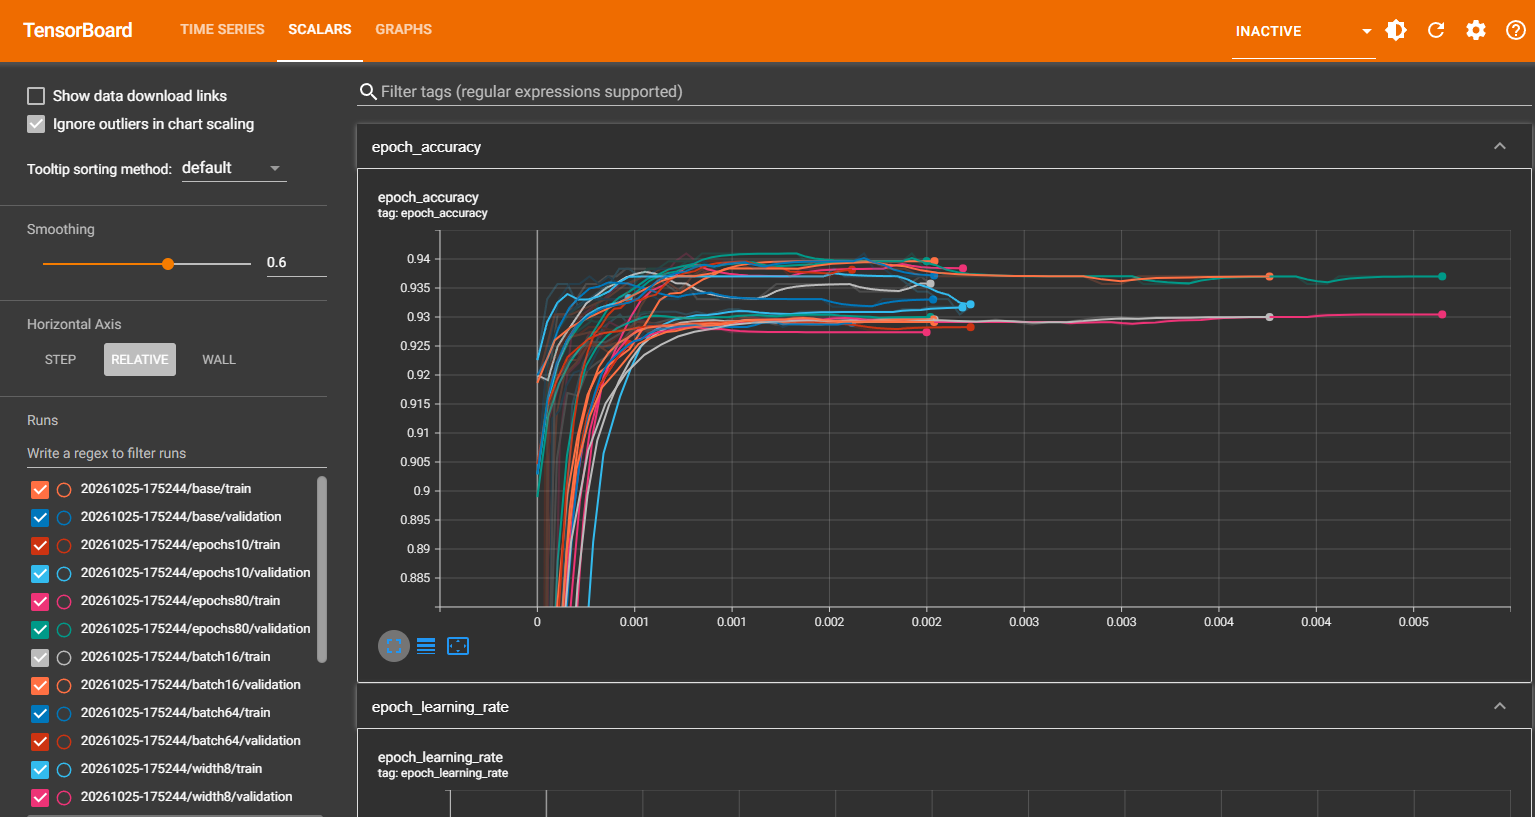

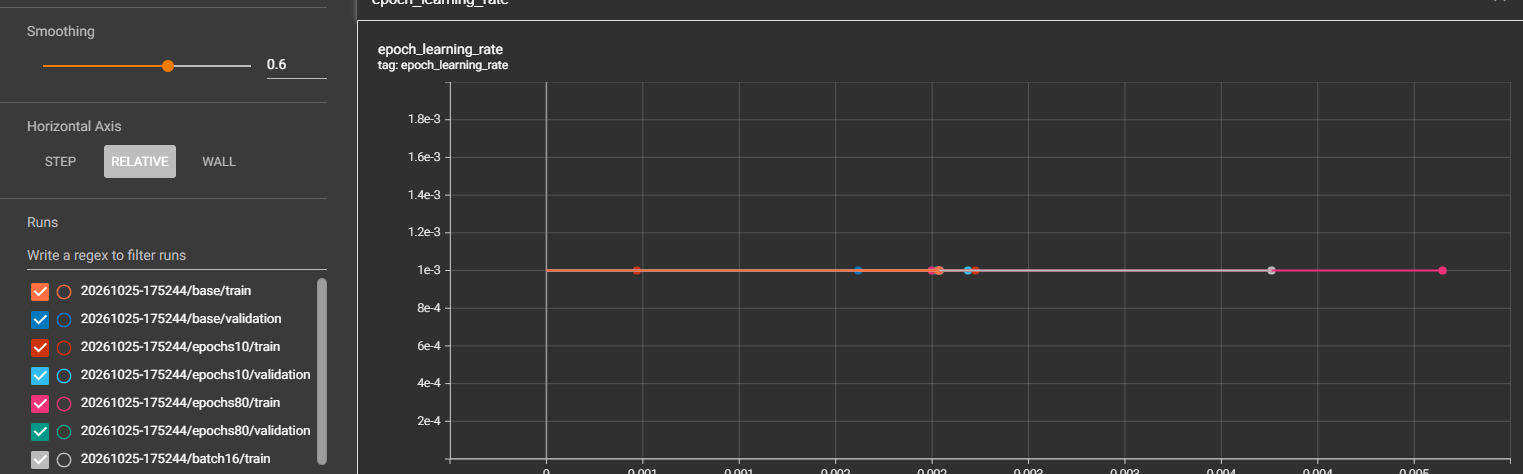

## 7. Сравнительный анализ

In [46]:
validation_rows.append({'Модель': 'TensorFlow MLP', **best_nn_metrics})
validation_table = pd.DataFrame(validation_rows)
best_method = validation_table.loc[validation_table['ROC-AUC'].idxmax(), 'Модель']
validation_table.to_csv(RESULTS / 'validation_metrics.csv', index=False)
print(validation_table.round(5).to_string(index=False))
print('Выбор по validation:', best_method)

        Модель  Accuracy  Precision  Recall      F1  ROC-AUC
    GaussianNB   0.92126    0.90798 0.90798 0.90798  0.97825
 MultinomialNB   0.91076    0.91083 0.87730 0.89375  0.97506
  ComplementNB   0.91207    0.90343 0.88957 0.89645  0.97506
   BernoulliNB   0.91995    0.88406 0.93558 0.90909  0.95886
 Decision Tree   0.93963    0.92683 0.93252 0.92966  0.97876
           LDA   0.93176    0.93082 0.90798 0.91925  0.98051
           SVM   0.93701    0.91867 0.93558 0.92705  0.98069
           kNN   0.93570    0.92355 0.92638 0.92496  0.97623
TensorFlow MLP   0.93438    0.91566 0.93252 0.92401  0.98012
Выбор по validation: SVM


В одной таблице сравниваются результаты на общей validation: восемь классических методов с параметрами из CV и лучший нейросетевой вариант. `idxmax()` выбирает строку с максимальным ROC-AUC; при точном совпадении сохраняется первая строка. Выбранный подход фиксируется до вычисления тестовых метрик. Различия предварительных CV-оценок и нейросетевой validation не смешиваются в одном рейтинге.

На validation выбран **SVM** с ROC-AUC **0,98069**. Этот выбор сохраняется при последующем рассмотрении тестовых результатов.

In [47]:
test_rows, test_scores, test_predictions = [], {}, {}
for name, model in best_models.items():
    prediction = model.predict(X_test)
    if name == 'SVM':
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]
    test_rows.append({'Модель': name, **calculate_metrics(y_test, prediction, scores)})
    test_scores[name], test_predictions[name] = scores, prediction

scores = best_network.predict(X_test_scaled, verbose=0).ravel()
prediction = (scores >= 0.5).astype(int)
test_rows.append({'Модель': 'TensorFlow MLP', **calculate_metrics(y_test, prediction, scores)})
test_scores['TensorFlow MLP'], test_predictions['TensorFlow MLP'] = scores, prediction
test_table = pd.DataFrame(test_rows)
test_table.to_csv(RESULTS / 'test_metrics.csv', index=False)
print(test_table.round(5).to_string(index=False))

predictions_table = pd.DataFrame({'row_id': y_test.index, 'y_true': y_test.to_numpy()})
for name in test_predictions:
    predictions_table[name + '__prediction'] = test_predictions[name]
    predictions_table[name + '__score'] = test_scores[name]
predictions_table.to_csv(RESULTS / 'test_predictions.csv', index=False)

        Модель  Accuracy  Precision  Recall      F1  ROC-AUC
    GaussianNB   0.90157    0.89590 0.87117 0.88336  0.97062
 MultinomialNB   0.89633    0.89457 0.85890 0.87637  0.96794
  ComplementNB   0.89895    0.89274 0.86810 0.88025  0.96794
   BernoulliNB   0.89764    0.86686 0.89877 0.88253  0.94616
 Decision Tree   0.91601    0.89458 0.91104 0.90274  0.97257
           LDA   0.93701    0.93711 0.91411 0.92547  0.97819
           SVM   0.92520    0.90390 0.92331 0.91351  0.97782
           kNN   0.91470    0.89666 0.90491 0.90076  0.97380
TensorFlow MLP   0.91470    0.89189 0.91104 0.90137  0.97597


Все девять фиксированных моделей проверены на одних 762 тестовых объектах. В этом блоке вызывается только `predict`, обучение не выполняется. Метрики вычислены одной и той же функцией. Для SVM используется `decision_function`, у остальных методов – вероятность класса 1. Прогнозы и оценки каждого объекта сохранены в `test_predictions.csv`, итоговые показатели – в `test_metrics.csv`. Тестовые результаты не используются для изменения параметров задним числом.

Для выбранного **SVM** на test: Accuracy=0,92520, Precision=0,90390, Recall=0,92331, F1=0,91351, ROC-AUC=0,97782. Наибольший тестовый AUC описательно получен у **LDA**. Это не меняет выбор по validation задним числом.

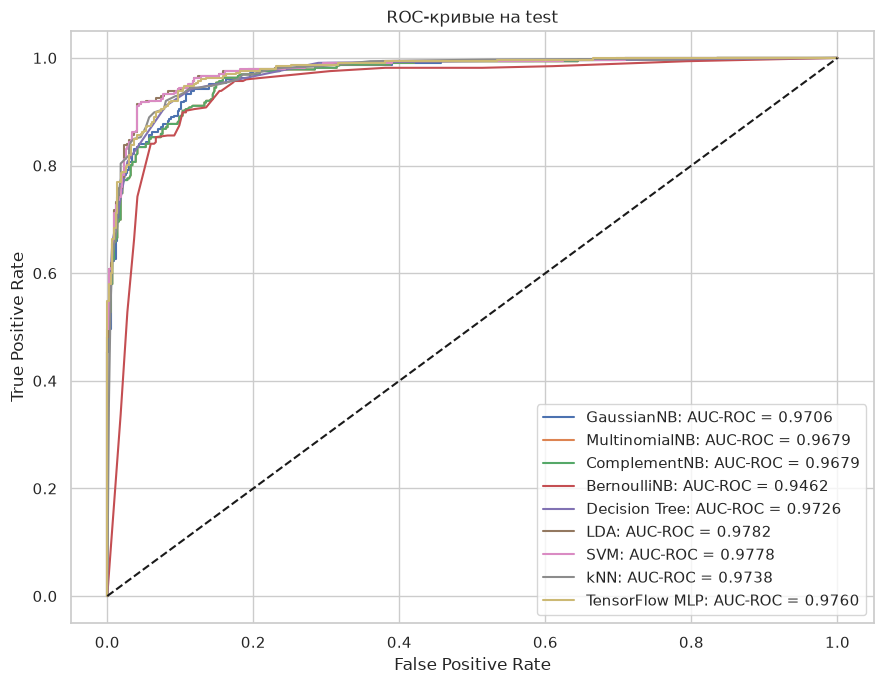

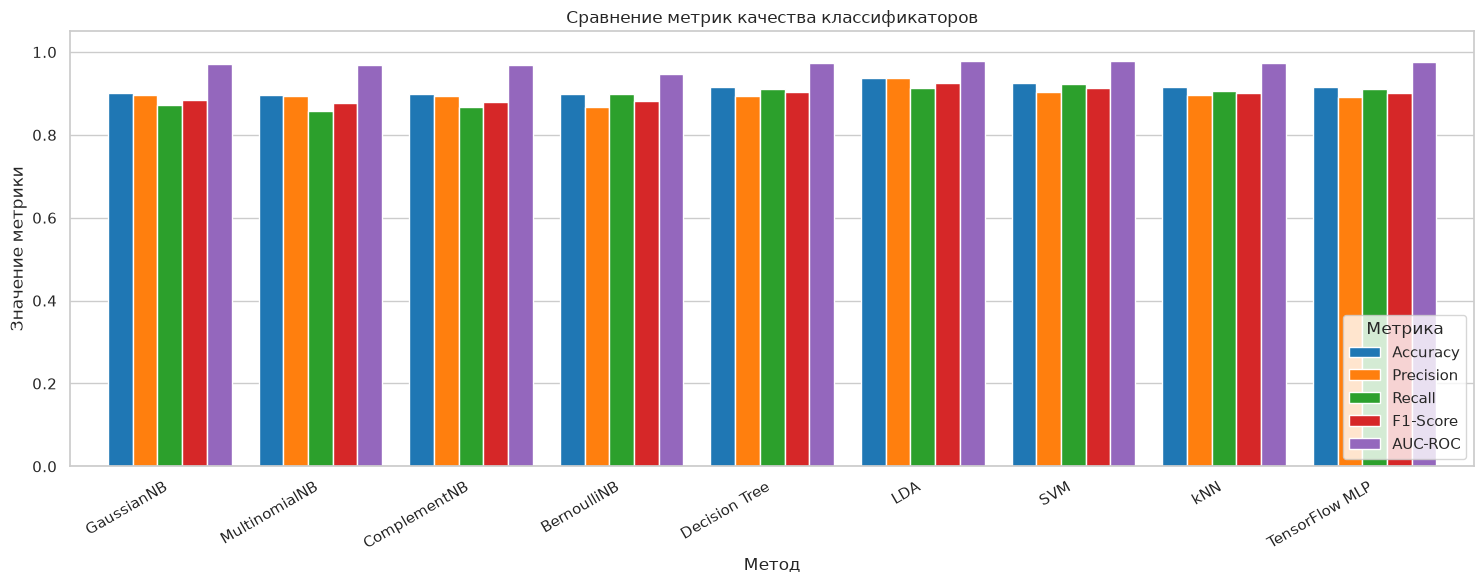

In [48]:
plt.figure(figsize=(9, 7))
for name, scores in test_scores.items():
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f'{name}: AUC-ROC = {roc_auc_score(y_test, scores):.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые на test')
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / '06_roc.png')
plt.show()

comparison = test_table.set_index('Модель')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']]
comparison = comparison.rename(columns={'F1': 'F1-Score', 'ROC-AUC': 'AUC-ROC'})
ax = comparison.plot(kind='bar', figsize=(15, 6), width=0.82,
                     color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
ax.set_title('Сравнение метрик качества классификаторов')
ax.set_xlabel('Метод')
ax.set_ylabel('Значение метрики')
ax.set_ylim(0, 1.05)
ax.legend(title='Метрика', loc='lower right')
ax.grid(axis='x', visible=False)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(PLOTS / '07_metrics.png', dpi=160)
plt.show()

ROC-кривые показывают соотношение чувствительности и доли ложных срабатываний при разных порогах. В легенде каждой кривой явно указан **AUC-ROC**. Диагональ соответствует случайному ранжированию.

На общей столбчатой диаграмме каждая группа – одна модель, а пять цветных столбцов – её метрики на тех же **762 тестовых объектах**:

- **Accuracy, синий:** доля правильных ответов среди всех объектов.
- **Precision, оранжевый:** доля настоящих Cammeo среди предсказанных Cammeo.
- **Recall, зелёный:** доля найденных Cammeo среди всех настоящих Cammeo.
- **F1-Score, красный:** гармоническое среднее Precision и Recall.
- **AUC-ROC, фиолетовый:** качество ранжирования по непрерывным оценкам при разных порогах.

Для всех пяти показателей большее значение соответствует лучшему результату. Шкала начинается с нуля; значения метрик лежат от 0 до 1. **AUC-ROC и ROC-AUC – обозначения одного показателя**: в CSV сохранено имя `ROC-AUC`. Его значение не равно доле правильных ответов и не определяется одним порогом.

На test **LDA** получил наибольшие Accuracy (**0,93701**), Precision (**0,93711**), F1 (**0,92547**) и AUC-ROC (**0,97819**). Наибольший Recall у **SVM – 0,92331**: он нашёл большую долю Cammeo, при этом его Precision ниже – **0,90390**. У нейросети Accuracy = **0,91470**, AUC-ROC = **0,97597**; усложнение метода не дало преимущества перед линейными классификаторами.

Разница тестового AUC между LDA и SVM составляет около **0,00037**; одного разбиения недостаточно, чтобы утверждать устойчивое превосходство. По заранее выбранному критерию validation предпочтён **SVM**; итоговые графики служат сравнению результатов, а не повторному подбору модели по test.

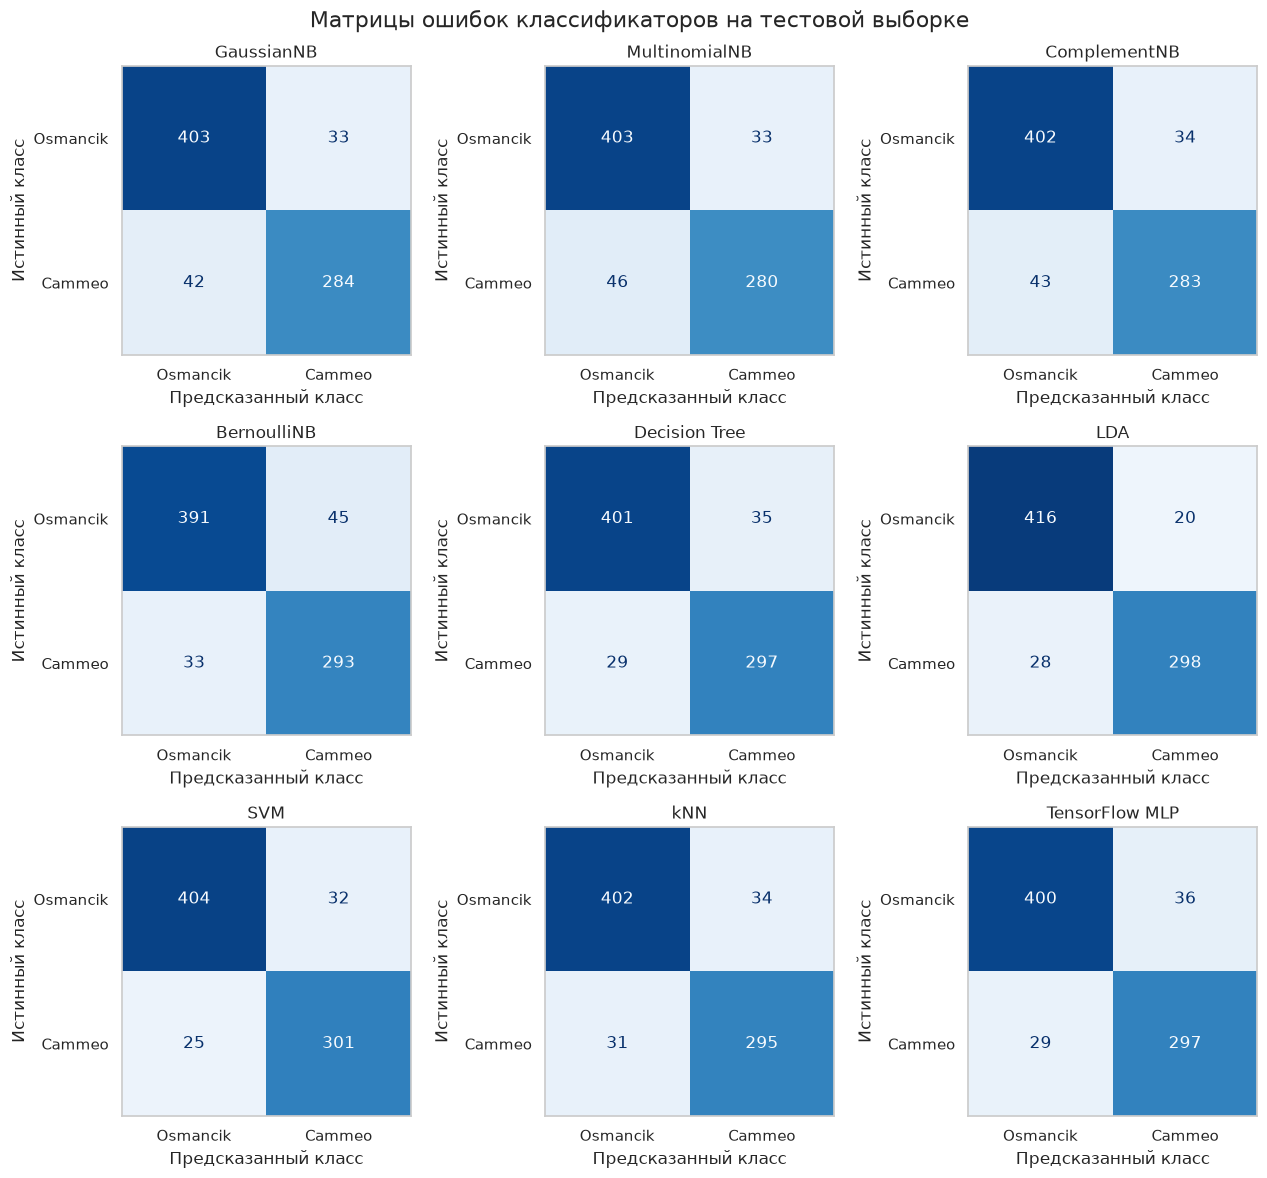

Логи TensorBoard: /home/tair/NETI/AI/lab2/logs/tensorboard/20261025-183428


In [49]:
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, (name, prediction) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=['Osmancik', 'Cammeo'],
        cmap='Blues', colorbar=False, values_format='d', ax=ax,
        im_kw={'vmin': 0, 'vmax': y_test.value_counts().max()},
    )
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.grid(False)
fig.suptitle('Матрицы ошибок классификаторов на тестовой выборке', fontsize=16)
plt.tight_layout()
plt.savefig(PLOTS / '08_confusion.png', dpi=150)
plt.show()

run_info = {'seed': SEED, 'train_size': len(X_train), 'validation_size': len(X_val),
            'test_size': len(X_test), 'best_method': best_method, 'best_nn_run': best_run,
            'tensorboard_dir': str(LOGS.relative_to(BASE)), 'nn_experiments': len(experiments)}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding='utf-8')
print('Логи TensorBoard:', LOGS)

Матрицы ошибок построены **для всех девяти моделей**, включая TensorFlow MLP, и расположены сеткой 3×3. Каждая модель проверена на одних **762 тестовых объектах**: 436 Osmancik и 326 Cammeo. Порядок классов и цветовая шкала одинаковы во всех панелях.

**Как читать матрицу:** строки – истинные классы, столбцы – прогнозы; первым указан Osmancik (0), вторым – Cammeo (1). Диагональ содержит правильные ответы. Для положительного класса Cammeo:

- **TN, слева вверху:** Osmancik правильно отнесён к Osmancik.
- **FP, справа вверху:** Osmancik ошибочно отнесён к Cammeo.
- **FN, слева внизу:** Cammeo ошибочно отнесён к Osmancik.
- **TP, справа внизу:** Cammeo правильно отнесён к Cammeo.

Числа на рисунках сведены в таблицу; всего ошибок = FP + FN:

| Модель | TN | FP | FN | TP | Всего ошибок |
| :--- | ---: | ---: | ---: | ---: | ---: |
| GaussianNB | 403 | 33 | 42 | 284 | 75 |
| MultinomialNB | 403 | 33 | 46 | 280 | 79 |
| ComplementNB | 402 | 34 | 43 | 283 | 77 |
| BernoulliNB | 391 | 45 | 33 | 293 | 78 |
| Decision Tree | 401 | 35 | 29 | 297 | 64 |
| LDA | 416 | 20 | 28 | 298 | 48 |
| SVM | 404 | 32 | 25 | 301 | 57 |
| kNN | 402 | 34 | 31 | 295 | 65 |
| TensorFlow MLP | 400 | 36 | 29 | 297 | 65 |

Наименьшее число тестовых ошибок у **LDA – 48**: 20 ложных отнесений Osmancik к Cammeo и 28 пропущенных Cammeo. У **SVM – 57 ошибок**: 32 FP и 25 FN. SVM пропускает меньше Cammeo и имеет более высокий Recall, а LDA даёт меньше ложных положительных ответов и более высокие Precision и Accuracy.

У **TensorFlow MLP – 65 ошибок**: 36 FP и 29 FN. Это сопоставимо с kNN (65 ошибок) и деревом решений (64 ошибки); нейросеть не превзошла LDA или SVM на данной тестовой выборке. У вариантов наивного Байеса от 75 до 79 ошибок.

Матрицы объясняют различия итоговых метрик. Выбор SVM, сделанный ранее по validation, сохраняется: сравнение тестовых ошибок не используется для повторной настройки. Показатели запуска и путь к TensorBoard сохранены в `run_info.json`.

## 8. Заключение

В работе исследованы восемь классических классификаторов и нейросеть. Параметры классических методов выбирались по пятикратной CV, нейросетевые конфигурации – по отдельной validation. Проверено влияние эпох, батчей, количества слоёв и нейронов, активаций. Для всех методов рассчитаны пять метрик на независимом test. Процесс обучения сохранён в TensorBoard.

По заранее выбранному критерию validation ROC-AUC предпочтён **SVM**. На независимом test: **Accuracy=0,92520, F1=0,91351, ROC-AUC=0,97782**. Усложнение модели не гарантирует улучшения качества; сравнивать методы необходимо по выбранной метрике и на одинаковых данных. Вывод ограничен данным разбиением и сеткой параметров, перенос на другие условия съёмки отдельно не проверялся.